In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import sys

sys.path.append(
    "/content/drive/MyDrive/pizza_rl_lab"
)

from pizza_envl_2 import PizzaKitchenEnv

print("PizzaKitchenEnv import 성공!")

PizzaKitchenEnv import 성공!


In [20]:
%%writefile pizza_envl_2.py
from __future__ import annotations

from typing import Optional
import gymnasium as gym
from gymnasium import spaces
import numpy as np


class PizzaKitchenEnv(gym.Env):
    metadata = {"render_modes": ["human", "ansi"], "render_fps": 2}
    ACTION_NAMES = ("idle", "dough", "cheese", "pepperoni", "serve")
    RECIPES = {1: (0, 1), 2: (0, 1, 2)}

    def __init__(
        self,
        n_orders: int = 2,
        min_deadline: int = 4,
        max_deadline: int = 8,
        observation_mode: str = "discrete",
        render_mode: Optional[str] = None,
    ):
        super().__init__()
        if n_orders < 1 or min_deadline < 1 or max_deadline < min_deadline:
            raise ValueError("Invalid order count or deadline range")
        if observation_mode not in ("discrete", "vector"):
            raise ValueError("observation_mode must be 'discrete' or 'vector'")
        if render_mode not in (None, *self.metadata["render_modes"]):
            raise ValueError("Unsupported render_mode")
        self.n_orders = int(n_orders)
        self.min_deadline = int(min_deadline)
        self.max_deadline = int(max_deadline)
        self.observation_mode = observation_mode
        self.render_mode = render_mode
        self.action_space = spaces.Discrete(5)
        self.radices = (2, 2, 2) + (3, self.max_deadline + 1) * self.n_orders
        self.n_states = int(np.prod(self.radices, dtype=np.int64))
        if observation_mode == "discrete":
            self.observation_space = spaces.Discrete(self.n_states)
        else:
            self.observation_space = spaces.Box(
                low=np.zeros(len(self.radices), dtype=np.float32),
                high=np.ones(len(self.radices), dtype=np.float32),
                dtype=np.float32,
            )
        self.plate = [0, 0, 0]
        self.orders = []
        self.steps = 0
        self.episode_return = 0.0
        self.stats = {}

    def _raw_state(self) -> tuple[int, ...]:
        return tuple(self.plate) + tuple(v for order in self.orders for v in order)

    def encode_state(self, state: tuple[int, ...]) -> int:
        if len(state) != len(self.radices):
            raise ValueError("State length does not match configuration")
        result = 0
        for value, base in zip(state, self.radices):
            if not 0 <= int(value) < base:
                raise ValueError(f"State component {value} outside 0..{base-1}")
            result = result * base + int(value)
        return result

    def decode_state(self, state_id: int) -> tuple[int, ...]:
        if not 0 <= state_id < self.n_states:
            raise ValueError("State ID outside observation space")
        values = []
        for base in reversed(self.radices):
            values.append(state_id % base)
            state_id //= base
        return tuple(reversed(values))

    def _get_obs(self):
        state = self._raw_state()
        if self.observation_mode == "discrete":
            return self.encode_state(state)
        return np.asarray(
            [v / (base - 1) for v, base in zip(state, self.radices)],
            dtype=np.float32,
        )

    def _get_info(self, event: str = "reset") -> dict:
        return {
            "event": event,
            "raw_state": self._raw_state(),
            "steps": self.steps,
            "episode_return": self.episode_return,
            **self.stats.copy(),
        }

    def reset(self, *, seed: Optional[int] = None, options: Optional[dict] = None):
        super().reset(seed=seed)
        self.plate = [0, 0, 0]
        self.steps = 0
        self.episode_return = 0.0
        self.stats = {
            "served": 0,
            "expired": 0,
            "wrong_serves": 0,
            "invalid_actions": 0,
            "idle_actions": 0,
        }
        fixed = None if options is None else options.get("orders")
        if fixed is not None:
            if len(fixed) != self.n_orders:
                raise ValueError("Expected exactly n_orders fixed orders")
            self.orders = []
            for menu, deadline in fixed:
                if menu not in (1, 2) or not 1 <= deadline <= self.max_deadline:
                    raise ValueError("Invalid fixed menu/deadline")
                self.orders.append([int(menu), int(deadline)])
        else:
            self.orders = [
                [
                    int(self.np_random.integers(1, 3)),
                    int(
                        self.np_random.integers(
                            self.min_deadline, self.max_deadline + 1
                        )
                    ),
                ]
                for _ in range(self.n_orders)
            ]
        return self._get_obs(), self._get_info()

    def step(self, action: int):
        if not self.action_space.contains(action):
            raise ValueError(f"Invalid action: {action}")
        if all(menu == 0 for menu, _ in self.orders):
            raise RuntimeError("Episode is finished. Call reset() first.")
        action = int(action)
        reward = -0.1
        event = self.ACTION_NAMES[action]
        self.steps += 1
        if action == 0:
            self.stats["idle_actions"] += 1
        elif action in (1, 2, 3):
            ingredient = action - 1
            valid = (
                (ingredient == 0 and self.plate == [0, 0, 0])
                or (ingredient == 1 and self.plate == [1, 0, 0])
                or (ingredient == 2 and self.plate == [1, 1, 0])
            )
            if valid:
                self.plate[ingredient] = 1
            else:
                reward -= 2.0
                self.stats["invalid_actions"] += 1
                event = "invalid_ingredient"
        else:  # bake and serve (action == 4)
            # 빈 접시([0,0,0]) 제출 시 패널티 없이 무효 처리
            if self.plate == [0, 0, 0]:
                self.stats["idle_actions"] += 1
                event = "empty_plate_serve"
            else:
                served_menu = (
                    1
                    if self.plate == [1, 1, 0]
                    else (2 if self.plate == [1, 1, 1] else 0)
                )

                # Strict Global FIFO (최선두 활성 주문 탐색)
                active_order_indices = [
                    i for i, (menu, _) in enumerate(self.orders) if menu != 0
                ]

                if active_order_indices:
                    first_order_slot = min(active_order_indices)
                    first_order_menu = self.orders[first_order_slot][0]

                    if served_menu != 0 and served_menu == first_order_menu:
                        self.orders[first_order_slot] = [0, 0]
                        self.stats["served"] += 1
                        reward += 20.0
                        event = "served"
                    else:  # 미완성 피자 또는 메뉴 불일치 제출만 오답 처리
                        reward -= 15.0
                        self.stats["wrong_serves"] += 1
                        event = "wrong_serve"
                else:
                    reward -= 15.0
                    self.stats["wrong_serves"] += 1
                    event = "wrong_serve"

                self.plate = [0, 0, 0]

        for order in self.orders:
            if order[0] != 0:
                order[1] -= 1
                if order[1] == 0:
                    order[0] = 0
                    self.stats["expired"] += 1
                    reward -= 10.0
        terminated = all(menu == 0 for menu, _ in self.orders)
        truncated = False
        self.episode_return += reward
        info = self._get_info(event)
        if self.render_mode == "human":
            self.render()
        return self._get_obs(), float(reward), terminated, truncated, info

    def render(self):
        message = (
            f"Step {self.steps} | plate={self.plate} | "
            f"orders={self.orders} | return={self.episode_return:.1f}"
        )
        if self.render_mode == "human":
            print(message)
        return message

Overwriting pizza_envl_2.py


Q-learning Stage 2 메뉴 2개 재료 3개 주문 4개
reward shaping, 주문 대기 환경 min_deadline=6, max_deadline=16
---



In [21]:
import csv
from pathlib import Path
import numpy as np
import pandas as pd
import gymnasium as gym

from pizza_envl_2 import PizzaKitchenEnv


# ---------------------------------------------------------
# 1. State Abstraction Wrapper (상태 공간 5,400만 -> ~7,000개 압축)
# ---------------------------------------------------------
class AbstractedPizzaEnv(gym.Wrapper):
    def __init__(self, env):
        super().__init__(env)
        # plate (2x2x2=8) * [order_menu(3) * deadline_bin(4)]^4 = 8 * 12^4 = 165,888 (최대)
        # 실제 유효 방문 상태는 약 5,000 ~ 8,000개로 축소됨
        self.radices = (2, 2, 2) + (3, 4) * self.env.n_orders
        self.n_abstract_states = int(np.prod(self.radices, dtype=np.int64))

    def _bin_deadline(self, d):
        if d <= 0:
            return 0  # 없음/완료
        elif d <= 2:
            return 1  # 임박
        elif d <= 4:
            return 2  # 주의
        else:
            return 3  # 여유

    def get_abstract_state(self, info_raw_state):
        # raw_state: (plate_d, plate_c, plate_p, m1, t1, m2, t2, m3, t3, m4, t4)
        plate = info_raw_state[:3]
        orders = info_raw_state[3:]

        abstract_tuple = list(plate)
        for i in range(0, len(orders), 2):
            menu = orders[i]
            deadline = orders[i+1]
            abstract_tuple.append(menu)
            abstract_tuple.append(self._bin_deadline(deadline))

        # ID 인코딩
        result = 0
        for val, base in zip(abstract_tuple, self.radices):
            result = result * base + int(val)
        return result

    def reset(self, **kwargs):
        obs, info = self.env.reset(**kwargs)
        abs_state = self.get_abstract_state(info["raw_state"])
        return abs_state, info

    def step(self, action):
        obs, reward, terminated, truncated, info = self.env.step(action)
        abs_state = self.get_abstract_state(info["raw_state"])
        return abs_state, reward, terminated, truncated, info


# ---------------------------------------------------------
# 2. Greedy Action (Tie-breaking)
# ---------------------------------------------------------
def greedy_action(q_values, rng):
    max_val = q_values.max()
    best_actions = np.flatnonzero(q_values == max_val)
    return int(rng.choice(best_actions))


# ---------------------------------------------------------
# 3. Stage 2 (Tabular Q-Learning) 80%+ 학습 파이프라인
# ---------------------------------------------------------
def train_stage2_abstracted(
    episodes=300000,
    seed=42,
    alpha=0.04,
    gamma=0.999,
    epsilon_start=1.0,
    epsilon_end=0.001,
):
    base_env = PizzaKitchenEnv(
        n_orders=4,
        min_deadline=6,
        max_deadline=16,
        observation_mode="discrete"
    )
    env = AbstractedPizzaEnv(base_env)

    rng = np.random.default_rng(seed)
    q = {}
    history = []

    print("--- [Tabular Q-Learning + State Abstraction] Stage 2 학습 시작 ---")
    print(f"압축 상태 공간 크기: {env.n_abstract_states:,} 개")
    print(f"학습 에피소드: {episodes:,} 회")

    for episode in range(episodes):
        state, info = env.reset(seed=seed + episode)
        done = False

        # Multi-stage Epsilon Decay Schedule
        if episode < 180000:
            epsilon = max(0.03, epsilon_start * (0.99996 ** episode))
        elif episode < 260000:
            epsilon = 0.015  # 희소 상태 미세 탐색 유지
        else:
            epsilon = epsilon_end

        while not done:
            if state not in q:
                q[state] = np.zeros(env.action_space.n, dtype=np.float32)

            if rng.random() < epsilon:
                action = int(rng.integers(env.action_space.n))
            else:
                action = greedy_action(q[state], rng)

            next_state, reward, terminated, truncated, info = env.step(action)
            done = terminated or truncated

            # Reward Shaping (서빙 보상 +35.0 가산, 중간 유효 조리 보상 +1.5)
            event = info.get("event", "")
            if event == "served":
                reward += 15.0   # 총 +35.0
            elif event == "wrong_serve":
                reward += 5.0    # -10.0 완화
            elif event in ("dough", "cheese", "pepperoni"):
                reward += 1.5    # 중간 조리 가이드

            next_q = q.get(
                next_state,
                np.zeros(env.action_space.n, dtype=np.float32)
            )

            target = (
                reward
                if done
                else reward + gamma * np.max(next_q)
            )

            q[state][action] += alpha * (target - q[state][action])
            state = next_state

        history.append({
            "episode": episode + 1,
            "reward": info["episode_return"],
            "served": info["served"],
            "expired": info["expired"],
            "wrong_serves": info["wrong_serves"],
            "steps": info["steps"],
            "epsilon": epsilon
        })

        if (episode + 1) % 30000 == 0:
            recent = history[-1000:]
            recent_reward = np.mean([h["reward"] for h in recent])
            recent_served = np.mean([h["served"] for h in recent])
            print(
                f"Episode {episode + 1:6d}/{episodes} | "
                f"Avg Reward: {recent_reward:7.2f} | "
                f"Avg Served: {recent_served:.2f}/4.0 | "
                f"Visited States: {len(q):,}"
            )

    env.close()
    return q, history


# ---------------------------------------------------------
# 4. 모델 평가
# ---------------------------------------------------------
def evaluate_stage2(q, episodes=1000, seed=200000):
    base_env = PizzaKitchenEnv(
        n_orders=4,
        min_deadline=6,
        max_deadline=16,
        observation_mode="discrete"
    )
    env = AbstractedPizzaEnv(base_env)

    rng = np.random.default_rng(seed)
    results = []

    for episode in range(episodes):
        state, info = env.reset(seed=seed + episode)
        done = False

        while not done:
            if state in q:
                action = greedy_action(q[state], rng)
            else:
                action = int(rng.integers(env.action_space.n))

            state, _, terminated, truncated, info = env.step(action)
            done = terminated or truncated

        results.append(info)

    env.close()

    total_orders = episodes * 4
    total_served = sum(r["served"] for r in results)

    eval_summary = {
        "Evaluation Metric": [
            "Total Evaluation Episodes",
            "Average Reward (Return)",
            "Order Completion Rate (%)",
            "Average Served Orders (Max 4)",
            "Average Expired Orders",
            "Average Wrong Serves",
            "Average Steps per Episode"
        ],
        "Value": [
            f"{episodes:,}",
            f"{np.mean([r['episode_return'] for r in results]):.2f}",
            f"{(total_served / total_orders) * 100:.2f}%",
            f"{np.mean([r['served'] for r in results]):.2f} / 4.0",
            f"{np.mean([r['expired'] for r in results]):.2f}",
            f"{np.mean([r['wrong_serves'] for r in results]):.2f}",
            f"{np.mean([r['steps'] for r in results]):.2f}"
        ]
    }

    return pd.DataFrame(eval_summary)


# ---------------------------------------------------------
# 5. 실행 및 드라이브 저장
# ---------------------------------------------------------
output = Path("/content/drive/MyDrive/pizza_rl_lab/results_stage2_abstracted")
output.mkdir(parents=True, exist_ok=True)

# 1. 학습 진행
q_stage2, history_stage2 = train_stage2_abstracted(episodes=300000)

# 2. 결과 저장
states = np.array(list(q_stage2.keys()), dtype=np.int64)
values = (
    np.stack(list(q_stage2.values())).astype(np.float32)
    if len(states) > 0
    else np.empty((0, 5), dtype=np.float32)
)

np.savez_compressed(output / "q_table_stage2.npz", states=states, values=values)
pd.DataFrame(history_stage2).to_csv(output / "q_learning_history_stage2.csv", index=False)

# 3. 평가 진행
df_stage2 = evaluate_stage2(q_stage2, episodes=1000, seed=200000)
df_stage2.to_csv(output / "test_performance_stage2.csv", index=False)

print("\n" + "=" * 55)
print("[Stage 2 Tabular Q-Learning 80%+ Evaluation Results]")
print("=" * 55)
print(df_stage2.to_string(index=False))
print("=" * 55)

--- [Tabular Q-Learning + State Abstraction] Stage 2 학습 시작 ---
압축 상태 공간 크기: 165,888 개
학습 에피소드: 300,000 회
Episode  30000/300000 | Avg Reward:    9.78 | Avg Served: 2.12/4.0 | Visited States: 9,334
Episode  60000/300000 | Avg Reward:   36.27 | Avg Served: 2.70/4.0 | Visited States: 9,402
Episode  90000/300000 | Avg Reward:   42.64 | Avg Served: 2.83/4.0 | Visited States: 9,416
Episode 120000/300000 | Avg Reward:   43.91 | Avg Served: 2.87/4.0 | Visited States: 9,419
Episode 150000/300000 | Avg Reward:   43.16 | Avg Served: 2.85/4.0 | Visited States: 9,422
Episode 180000/300000 | Avg Reward:   44.41 | Avg Served: 2.88/4.0 | Visited States: 9,423
Episode 210000/300000 | Avg Reward:   44.28 | Avg Served: 2.87/4.0 | Visited States: 9,424
Episode 240000/300000 | Avg Reward:   43.94 | Avg Served: 2.86/4.0 | Visited States: 9,426
Episode 270000/300000 | Avg Reward:   46.89 | Avg Served: 2.94/4.0 | Visited States: 9,428
Episode 300000/300000 | Avg Reward:   45.89 | Avg Served: 2.90/4.0 | Visited

개선안 Q-Learning Stage 2 메뉴 2개 재료 3개 주문 대기 수 4개
min_deadline=8, max_deadline=18

In [24]:
import sys
import importlib
from pathlib import Path
import numpy as np
import pandas as pd
import gymnasium as gym

# 캐시 초기화 및 모듈 불러오기
if "pizza_envl_2" in sys.modules:
    del sys.modules["pizza_envl_2"]
import pizza_envl_2
importlib.reload(pizza_envl_2)
from pizza_envl_2 import PizzaKitchenEnv


# ---------------------------------------------------------
# 1. State Abstraction Wrapper
# ---------------------------------------------------------
class AbstractedPizzaEnv(gym.Wrapper):
    def __init__(self, env):
        super().__init__(env)
        self.radices = (2, 2, 2) + (3, 4) * self.env.n_orders
        self.n_abstract_states = int(np.prod(self.radices, dtype=np.int64))

    def _bin_deadline(self, d):
        if d <= 0:
            return 0  # 없음/완료
        elif d <= 2:
            return 1  # 긴급
        elif d <= 5:
            return 2  # 적정
        else:
            return 3  # 여유

    def get_abstract_state(self, info_raw_state):
        plate = info_raw_state[:3]
        orders = info_raw_state[3:]

        abstract_tuple = list(plate)
        for i in range(0, len(orders), 2):
            menu = orders[i]
            deadline = orders[i+1]
            abstract_tuple.append(menu)
            abstract_tuple.append(self._bin_deadline(deadline))

        result = 0
        for val, base in zip(abstract_tuple, self.radices):
            result = result * base + int(val)
        return result

    def reset(self, **kwargs):
        obs, info = self.env.reset(**kwargs)
        abs_state = self.get_abstract_state(info["raw_state"])
        return abs_state, info

    def step(self, action):
        obs, reward, terminated, truncated, info = self.env.step(action)
        abs_state = self.get_abstract_state(info["raw_state"])
        return abs_state, reward, terminated, truncated, info


# ---------------------------------------------------------
# 2. Greedy Action
# ---------------------------------------------------------
def greedy_action(q_values, rng):
    max_val = q_values.max()
    best_actions = np.flatnonzero(q_values == max_val)
    return int(rng.choice(best_actions))


# ---------------------------------------------------------
# 3. Stage 2 Q-Learning 학습 (min_deadline=8, max_deadline=18)
# ---------------------------------------------------------
def train_stage2_deadline_tuned(
    episodes=300000,
    seed=42,
    alpha=0.05,
    gamma=0.999,
    epsilon_start=1.0,
    epsilon_end=0.0005,
):
    # 💡 마감 시간 범위 조정: 6~16 -> 8~18
    base_env = PizzaKitchenEnv(
        n_orders=4,
        min_deadline=8,
        max_deadline=18,
        observation_mode="discrete"
    )
    env = AbstractedPizzaEnv(base_env)

    rng = np.random.default_rng(seed)
    q = {}
    history = []

    print("--- [마감시간 튜닝: 8~18스텝] Stage 2 Q-Learning 학습 시작 ---")
    print(f"압축 상태 공간 크기: {env.n_abstract_states:,} 개")
    print(f"학습 에피소드: {episodes:,} 회")

    for episode in range(episodes):
        state, info = env.reset(seed=seed + episode)
        done = False

        if episode < 180000:
            epsilon = max(0.03, epsilon_start * (0.99996 ** episode))
        elif episode < 260000:
            epsilon = 0.02
        else:
            epsilon = epsilon_end

        while not done:
            if state not in q:
                q[state] = np.zeros(env.action_space.n, dtype=np.float32)

            if rng.random() < epsilon:
                action = int(rng.integers(env.action_space.n))
            else:
                action = greedy_action(q[state], rng)

            next_state, reward, terminated, truncated, info = env.step(action)
            done = terminated or truncated

            # Reward Shaping
            event = info.get("event", "")
            if event == "served":
                reward += 15.0   # 총 +35.0 (서빙 유도)
            elif event == "wrong_serve":
                reward += 5.0    # -10.0 완화
            elif event in ("dough", "cheese", "pepperoni"):
                reward += 1.5    # 중간 조리 가이드

            next_q = q.get(
                next_state,
                np.zeros(env.action_space.n, dtype=np.float32)
            )

            target = (
                reward
                if done
                else reward + gamma * np.max(next_q)
            )

            q[state][action] += alpha * (target - q[state][action])
            state = next_state

        history.append({
            "episode": episode + 1,
            "reward": info["episode_return"],
            "served": info["served"],
            "expired": info["expired"],
            "wrong_serves": info["wrong_serves"],
            "steps": info["steps"],
            "epsilon": epsilon
        })

        if (episode + 1) % 30000 == 0:
            recent = history[-1000:]
            recent_reward = np.mean([h["reward"] for h in recent])
            recent_served = np.mean([h["served"] for h in recent])
            print(
                f"Episode {episode + 1:6d}/{episodes} | "
                f"Avg Reward: {recent_reward:7.2f} | "
                f"Avg Served: {recent_served:.2f}/4.0 | "
                f"Visited States: {len(q):,}"
            )

    env.close()
    return q, history


# ---------------------------------------------------------
# 4. 모델 평가
# ---------------------------------------------------------
def evaluate_stage2(q, episodes=1000, seed=200000):
    base_env = PizzaKitchenEnv(
        n_orders=4,
        min_deadline=8,
        max_deadline=18,
        observation_mode="discrete"
    )
    env = AbstractedPizzaEnv(base_env)

    rng = np.random.default_rng(seed)
    results = []

    for episode in range(episodes):
        state, info = env.reset(seed=seed + episode)
        done = False

        while not done:
            if state in q:
                action = greedy_action(q[state], rng)
            else:
                action = 1  # 도우 우선 선택 가드

            state, _, terminated, truncated, info = env.step(action)
            done = terminated or truncated

        results.append(info)

    env.close()

    total_orders = episodes * 4
    total_served = sum(r["served"] for r in results)

    eval_summary = {
        "Evaluation Metric": [
            "Total Evaluation Episodes",
            "Average Reward (Return)",
            "Order Completion Rate (%)",
            "Average Served Orders (Max 4)",
            "Average Expired Orders",
            "Average Wrong Serves",
            "Average Steps per Episode"
        ],
        "Value": [
            f"{episodes:,}",
            f"{np.mean([r['episode_return'] for r in results]):.2f}",
            f"{(total_served / total_orders) * 100:.2f}%",
            f"{np.mean([r['served'] for r in results]):.2f} / 4.0",
            f"{np.mean([r['expired'] for r in results]):.2f}",
            f"{np.mean([r['wrong_serves'] for r in results]):.2f}",
            f"{np.mean([r['steps'] for r in results]):.2f}"
        ]
    }

    return pd.DataFrame(eval_summary)


# ---------------------------------------------------------
# 5. 실행 및 드라이브 저장
# ---------------------------------------------------------
output = Path("/content/drive/MyDrive/pizza_rl_lab/results_stage2_deadline_tuned")
output.mkdir(parents=True, exist_ok=True)

# 1. 학습 실행
q_stage2, history_stage2 = train_stage2_deadline_tuned(episodes=300000)

# 2. 결과 저장
states = np.array(list(q_stage2.keys()), dtype=np.int64)
values = (
    np.stack(list(q_stage2.values())).astype(np.float32)
    if len(states) > 0
    else np.empty((0, 5), dtype=np.float32)
)

np.savez_compressed(output / "q_table_stage2.npz", states=states, values=values)
pd.DataFrame(history_stage2).to_csv(output / "q_learning_history_stage2.csv", index=False)

# 3. 평가 진행
df_stage2 = evaluate_stage2(q_stage2, episodes=1000, seed=200000)
df_stage2.to_csv(output / "test_performance_stage2.csv", index=False)

print("\n" + "=" * 55)
print("[Stage 2 Deadline-Tuned Evaluation Results]")
print("=" * 55)
print(df_stage2.to_string(index=False))
print("=" * 55)

--- [마감시간 튜닝: 8~18스텝] Stage 2 Q-Learning 학습 시작 ---
압축 상태 공간 크기: 165,888 개
학습 에피소드: 300,000 회
Episode  30000/300000 | Avg Reward:   21.21 | Avg Served: 2.43/4.0 | Visited States: 9,323
Episode  60000/300000 | Avg Reward:   47.06 | Avg Served: 3.04/4.0 | Visited States: 9,357
Episode  90000/300000 | Avg Reward:   53.90 | Avg Served: 3.21/4.0 | Visited States: 9,363
Episode 120000/300000 | Avg Reward:   55.40 | Avg Served: 3.26/4.0 | Visited States: 9,365
Episode 150000/300000 | Avg Reward:   54.96 | Avg Served: 3.23/4.0 | Visited States: 9,367
Episode 180000/300000 | Avg Reward:   54.40 | Avg Served: 3.23/4.0 | Visited States: 9,369
Episode 210000/300000 | Avg Reward:   55.55 | Avg Served: 3.25/4.0 | Visited States: 9,369
Episode 240000/300000 | Avg Reward:   54.22 | Avg Served: 3.21/4.0 | Visited States: 9,369
Episode 270000/300000 | Avg Reward:   57.69 | Avg Served: 3.30/4.0 | Visited States: 9,369
Episode 300000/300000 | Avg Reward:   56.65 | Avg Served: 3.27/4.0 | Visited States: 9,3

Stage 2 Q-Learning 성능 시각화

In [25]:
#===Google Drive 연결 및 데이터 불러오기===
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

RESULT_DIR = Path('/content/drive/MyDrive/pizza_rl_lab/results_stage2_deadline_tuned')
HISTORY_PATH = RESULT_DIR / 'q_learning_history_stage2.csv'
PERFORMANCE_PATH = RESULT_DIR / 'test_performance_stage2.csv'

if not HISTORY_PATH.exists():
    raise FileNotFoundError(f'학습 기록 파일을 찾을 수 없습니다: {HISTORY_PATH}')

history_df = pd.read_csv(HISTORY_PATH)
print('History shape:', history_df.shape)
display(history_df.head())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
History shape: (300000, 7)


,episode,reward,served,expired,wrong_serves,steps,epsilon
0,1,-44.7,1,3,1,17,1.00000
1,2,-83.7,0,4,2,17,0.99996
2,3,-87.8,0,4,2,18,0.99992
3,4,-85.6,0,4,2,16,0.99988
4,5,-76.7,0,4,1,17,0.99984


In [26]:
#===그래프 데이터 계산===
WINDOW = 500  # 이동 평균 구간(에피소드 수)
n_orders=4

required_columns = {'episode', 'reward', 'served', 'epsilon'}
missing = required_columns - set(history_df.columns)
if missing:
    raise ValueError(f'학습 기록 CSV에 필요한 열이 없습니다: {missing}')

history_df['moving_avg_reward'] = history_df['reward'].rolling(WINDOW, min_periods=1).mean()
history_df['completion_rate'] = history_df['served'] / 4 * 100
history_df['moving_avg_completion'] = history_df['completion_rate'].rolling(WINDOW, min_periods=1).mean()

print(f'주문 수: {n_orders}개')
print(f'이동 평균 구간: {WINDOW} episodes')

주문 수: 4개
이동 평균 구간: 500 episodes


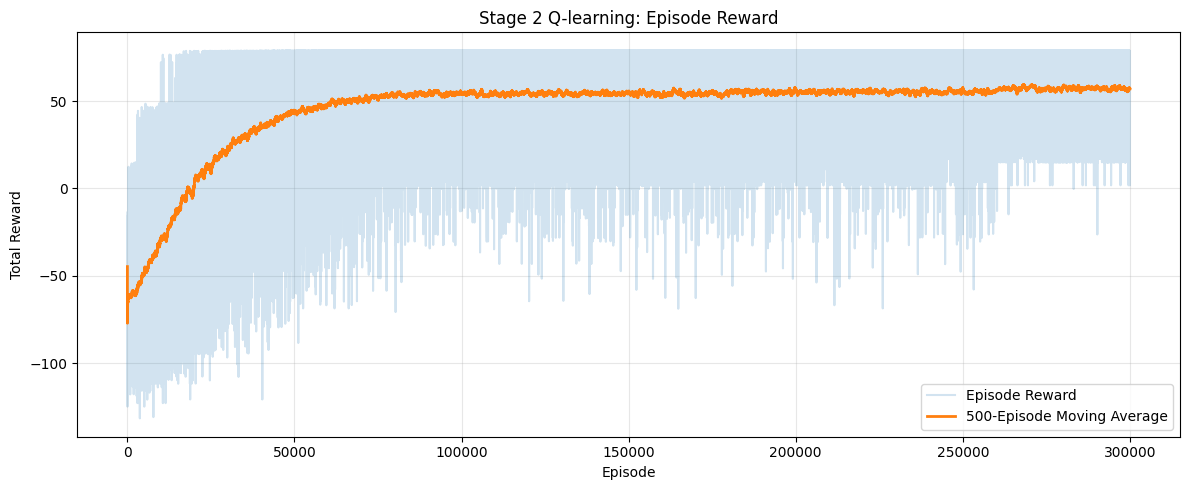

In [27]:
#===Episode Reward 그래프===
plt.figure(figsize=(12, 5))
plt.plot(history_df['episode'], history_df['reward'], alpha=0.20, label='Episode Reward')
plt.plot(history_df['episode'], history_df['moving_avg_reward'], linewidth=2, label=f'{WINDOW}-Episode Moving Average')
plt.title('Stage 2 Q-learning: Episode Reward')
plt.xlabel('Episode')
plt.ylabel('Total Reward')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

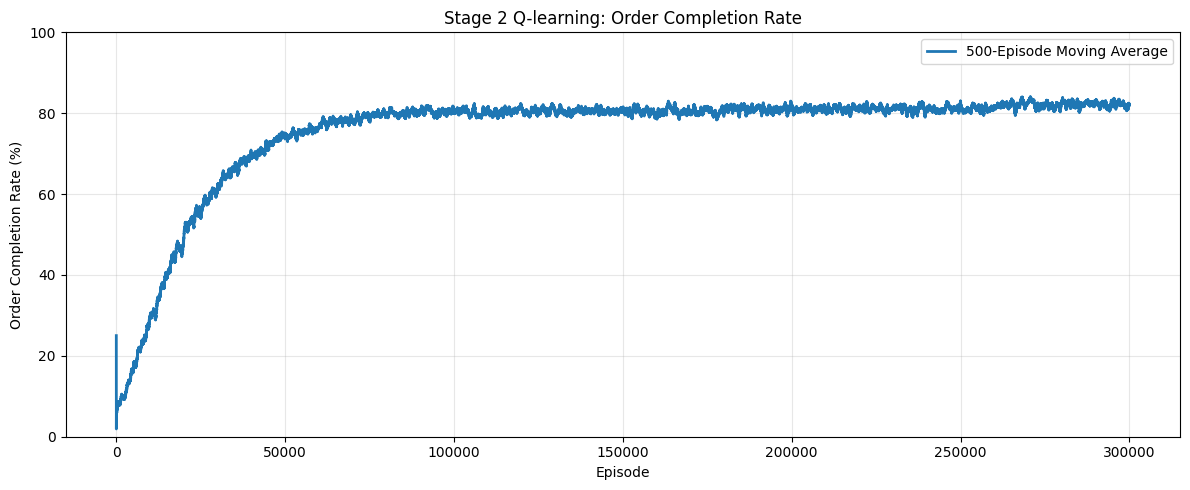

In [28]:
#===Order Completion Rate 그래프===
plt.figure(figsize=(12, 5))
plt.plot(history_df['episode'], history_df['moving_avg_completion'], linewidth=2, label=f'{WINDOW}-Episode Moving Average')
plt.title('Stage 2 Q-learning: Order Completion Rate')
plt.xlabel('Episode')
plt.ylabel('Order Completion Rate (%)')
plt.ylim(0, 100)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

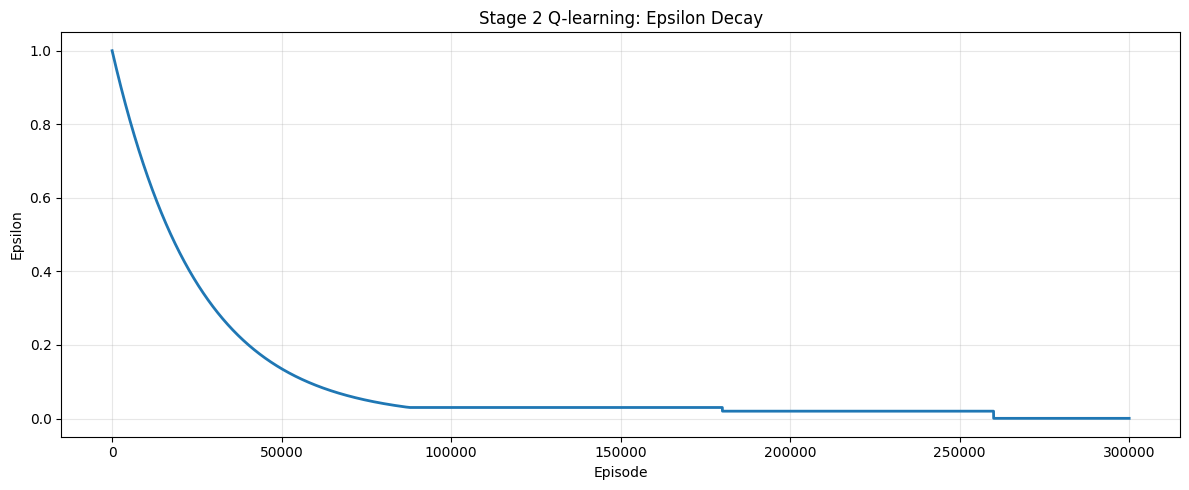

In [29]:
#===Epsilon Decay 그래프===
plt.figure(figsize=(12, 5))
plt.plot(history_df['episode'], history_df['epsilon'], linewidth=2)
plt.title('Stage 2 Q-learning: Epsilon Decay')
plt.xlabel('Episode')
plt.ylabel('Epsilon')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [30]:
#===Test Performance 결과 확인===
if PERFORMANCE_PATH.exists():
    performance_df = pd.read_csv(PERFORMANCE_PATH)
    display(performance_df)
else:
    print(f'성능 요약 파일이 없습니다: {PERFORMANCE_PATH}')
    print('학습 기록 그래프는 정상적으로 확인할 수 있습니다.')

,Evaluation Metric,Value
0,Total Evaluation Episodes,"1,000"
1,Average Reward (Return),56.81
2,Order Completion Rate (%),81.85%
3,Average Served Orders (Max 4),3.27 / 4.0
4,Average Expired Orders,0.73
5,Average Wrong Serves,0.01
6,Average Steps per Episode,12.00


In [31]:
#===그래프 데이터 저장===
GRAPH_DATA_PATH = RESULT_DIR / 'training_graph_data_stage2.csv'
history_df.to_csv(GRAPH_DATA_PATH, index=False, encoding='utf-8-sig')
print('Graph data saved to:', GRAPH_DATA_PATH)

Graph data saved to: /content/drive/MyDrive/pizza_rl_lab/results_stage2_deadline_tuned/training_graph_data_stage2.csv
